[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/grabuffo/brain-modeling-course/blob/main/notebooks/D2_C5_NB14a_silencing_a_hub.ipynb)

# Day 2 · Chapter 5 · Notebook 14a — Silencing a hub (exercise)

Take the Hopf model of NB10, push one region **far below its bifurcation** ($a=-5$) so that it damps whatever it
receives, and measure how the FC of the **rest** of the brain changes. This is the "local silencing" experiment of the
slides, done in the model. In pairs, about 25 minutes (Steps 1–4); Step 5 is for those who finish early; solutions at
the end.

> **Question.** Do hubs hold the network together, and does the model predict what silencing does in real brains?
> **Virtual experiment.** The same brain with the same noise, with and without one silenced region: a hub, a weakly
> connected region, and (Step 5) the region silenced in the mouse experiment of the slides.
> **What would change our mind.** If the model predicted the opposite of what the experiment measured, the model, not
> the experiment, would have to be revised.

<details><summary>Why a = −5 means "silenced"</summary>

In the Hopf model $a$ is the distance to the bifurcation. A region with a very negative $a$ forgets any input almost at
once: it no longer amplifies or relays activity. (In the neural-mass model of NB11 the corresponding knob is the
excitability $\eta$; we use it in NB14c.) All other regions stay at the working point of NB13, $a=-0.1$, $G=2$.
</details>

In [1]:
# @title Setup (run once)
# On Google Colab this downloads the course code; on your laptop it does nothing.
import sys, os
if "google.colab" in sys.modules:
    if not os.path.exists("/content/brain-modeling-course"):          # first run: download the course code
        !git clone -q https://github.com/grabuffo/brain-modeling-course.git /content/brain-modeling-course
        !pip -q install numba ipywidgets
    %cd /content/brain-modeling-course/notebooks
sys.path.insert(0, os.path.abspath(".."))   # so that `import src` works

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from src import plotting
from src.plotting import slider
plotting.setup()
from src import connectome
sc, fc, labels = connectome.load_hcp(weights="counts", normalize="rowsum", homotopic=0.5)   # same connectome as NB10
labels = [l.replace("7Networks_", "") for l in labels]
net = np.array([l.split("_")[1] for l in labels])
NETS = ["Vis", "SomMot", "DorsAttn", "SalVentAttn", "Limbic", "Cont", "Default"]
order = np.concatenate([np.where(net == n)[0] for n in NETS])
u = np.triu_indices(100, 1)
similarity = lambda A, B: np.corrcoef(A[u], B[u])[0, 1]

def show_matrix(ax, M, title, vmax=1.0):                           # matrix with regions grouped by network
    im = ax.imshow(M[np.ix_(order, order)], cmap="RdBu_r", vmin=-vmax, vmax=vmax); ax.set_title(title, fontsize=10)
    sizes = [np.sum(net == n) for n in NETS]; mids = np.cumsum([0] + sizes)
    for e in mids[1:-1] - 0.5: ax.axhline(e, c="k", lw=0.4); ax.axvline(e, c="k", lw=0.4)
    ax.set_xticks([]); ax.set_yticks((mids[:-1] + mids[1:]) / 2 - 0.5, NETS, fontsize=7)
    return im

def simulate(a, G, sigma=0.02, minutes=20, seed=0, f=0.05, dt=0.1, TR=2.0):
    # the Hopf whole-brain model of NB10; a can be one number or one value per region
    rng = np.random.default_rng(seed)
    N = len(sc); strength = sc.sum(1); omega = 2 * np.pi * f
    z = 0.1 * (rng.standard_normal(N) + 1j * rng.standard_normal(N))
    every, n_skip = int(TR / dt), int(60 / dt)
    out = []
    for k in range(n_skip + int(minutes * 60 / dt)):
        local = (a + 1j * omega) * z - np.abs(z) ** 2 * z
        coupling = G * (sc @ z - strength * z)
        noise = sigma * np.sqrt(dt) * (rng.standard_normal(N) + 1j * rng.standard_normal(N))
        z = z + dt * (local + coupling) + noise
        if k >= n_skip and (k - n_skip) % every == every - 1:
            out.append(z.real)
    return np.array(out)

def model_fc(a, G=2.0, runs=3):
    # average FC over a few 20-minute runs; the same noise (seeds) for every condition, so differences are due to a
    return np.mean([np.corrcoef(simulate(a, G, seed=s).T) for s in range(runs)], axis=0)

A0, G0 = -0.1, 2.0                                                   # working point of NB13 (best homogeneous fit)
base = model_fc(np.full(100, A0))
print(f"healthy model: similarity to measured FC {similarity(base, fc):.2f}, mean FC {base[u].mean():.3f}")

healthy model: similarity to measured FC 0.38, mean FC 0.087


## Step 1. Find the hubs

The **strength** of a region is the total weight of its connections **in the model**; hubs have the highest strength.

<details><summary>Why the hub list differs a little from NB12</summary>

NB12 counts fibres only. The model also contains the mirror links between hemispheres added in NB10 (weight 0.5 each).
For weakly wired regions these links are a large part of what they receive, so the ranking changes a little: NB12's
top hub (LH_Default_PFC_5) is second here. For a model experiment, what counts is the weight the model sees.
</details>

**Question 1.** Which are the five strongest hubs, and the five most weakly connected regions? To which networks do they
belong?

In [2]:
# Step 1: strength of every region
strength = (sc + sc.T).sum(1)                      # total weight in the model (fibres + mirror links)
rank = np.argsort(-strength)                       # strongest first
# your code: print the names (labels) and strengths of the 5 strongest and the 5 weakest regions

## Step 2. Silence the strongest hub

Set $a = -5$ in the strongest hub (all other regions stay at $a = -0.1$), compute the model FC, and subtract the healthy
FC: the **change** in FC.

**Question 2.** Which connections change? Only those of the hub, or also connections **between other regions**? Are
the regions whose FC changes most the direct neighbours of the hub? (A scatter plot of `change` against `W[hub]` answers
it.)

In [3]:
# Step 2: silence the strongest hub
hub = rank[0]
a = np.full(100, A0)
# your code: set a[hub] = -5, compute model_fc(a) and the change (silenced - base), then plot it:
#   fig, ax = plt.subplots(figsize=(5, 4.5)); show_matrix(ax, ___, "change in FC", vmax=0.05); plt.show()
# per-region change, for the second question (W = connection weights, others = all regions except the hub):
#   W = sc + sc.T; others = np.setdiff1d(np.arange(100), [hub])
#   change = np.abs(___[np.ix_(others, others)]).mean(1)            # mean |change| of each other region's FC
#   then plt.plot(W[hub, others], change, "o")

## Step 3. Silence a weakly connected region

To compare the two cases we need **one number**: how strongly the rest of the brain is correlated. The function
`fc_among_others(M, silenced)` below gives it:

1. it takes an FC matrix `M` (healthy or silenced);
2. it removes the row and the column of the silenced region(s);
3. it returns the **average FC over all the remaining pairs** of regions.

Why remove the silenced region? Once silenced, its own correlations drop to almost zero, which is trivial. The question
is whether the **other** regions, which were not touched, lose correlation **with each other**.

Compute this number for the healthy FC (`base`) and for the silenced FC, removing the same region in both, and
compare them as a percent change: `100 * (fc_among_others(silenced, [hub]) / fc_among_others(base, [hub]) - 1)`.
For example, 0.087 (healthy) → 0.078 (silenced) is −10%: the rest of the brain is 10% less correlated.

**Question 3.** Repeat Step 2 with the most weakly connected region (`rank[-1]`). Compute the percent change for the
hub and for the weak region: which one changes the FC among the other regions more?

In [4]:
# Step 3: silence the most weakly connected region
def fc_among_others(M, silenced):
    # average FC among the regions that were NOT silenced
    keep = np.setdiff1d(np.arange(100), silenced)            # all regions except the silenced one(s)
    M_keep = M[np.ix_(keep, keep)]                           # FC matrix without their rows and columns
    return M_keep[np.triu_indices(len(keep), 1)].mean()      # mean over all pairs (upper triangle, no diagonal)

# your code: percent change for the hub (Step 2) and for the weakest region, e.g.
#   100 * (fc_among_others(silenced_fc, [hub]) / fc_among_others(base, [hub]) - 1)

## Step 4. Five hubs, or five peripheral regions

**Question 4.** Silence the five strongest hubs together, then the five weakest regions. By how many percent does the
FC among the other regions drop? What does this say about the role of hubs?
Use the same percent change as in Step 3, now with the list of five silenced regions:
`100 * (fc_among_others(silenced, regions) / fc_among_others(base, regions) - 1)`.

In [5]:
# Step 4: five hubs, or five weakest regions
# your code

## Step 5 (extra, if you finish early). Does the model pass the test of the mouse experiment?

In the slides (Rocchi et al. 2022), chemogenetic silencing of the mouse **prefrontal cortex** made the FC between the
other regions **increase**. Do the same experiment in the model: silence the medial frontal regions (anterior cingulate,
the human counterpart of the silenced mouse area) and measure the FC among the other regions.

**Question 5.** Does the Hopf model predict an increase or a decrease? Is the answer the same closer to the bifurcation
($a=-0.02$ everywhere) or just past it ($a=+0.05$)? Does **any** pair of regions increase its FC?

In [6]:
# Step 5: silence the medial frontal regions, as in the mouse experiment
mpfc = [i for i, l in enumerate(labels) if "SalVentAttn_Med" in l]
print("silenced:", [labels[i] for i in mpfc])
# your code: a = np.full(100, A0); a[mpfc] = -5; compare fc_among_others(model_fc(a), mpfc) with the healthy value.
# For another working point, recompute the healthy FC too: model_fc(np.full(100, -0.02)).

silenced: ['LH_SalVentAttn_Med_1', 'LH_SalVentAttn_Med_2', 'LH_SalVentAttn_Med_3', 'RH_SalVentAttn_Med_1', 'RH_SalVentAttn_Med_2']


## Solutions (open after the exercise)

In [7]:
# @title Solution, step 1: hubs
for name, idx in [("strongest", rank[:5]), ("weakest", rank[-5:])]:
    print(name, ", ".join(f"{labels[i]} ({strength[i]:.2f})" for i in idx))

strongest RH_SalVentAttn_FrOperIns_1 (3.23), LH_Default_PFC_5 (3.00), RH_Vis_2 (2.86), RH_Vis_4 (2.84), LH_SomMot_6 (2.75)
weakest RH_Vis_5 (1.23), RH_Default_Par_1 (0.47), RH_SomMot_7 (0.43), RH_Cont_Par_1 (0.40), RH_SomMot_5 (0.39)


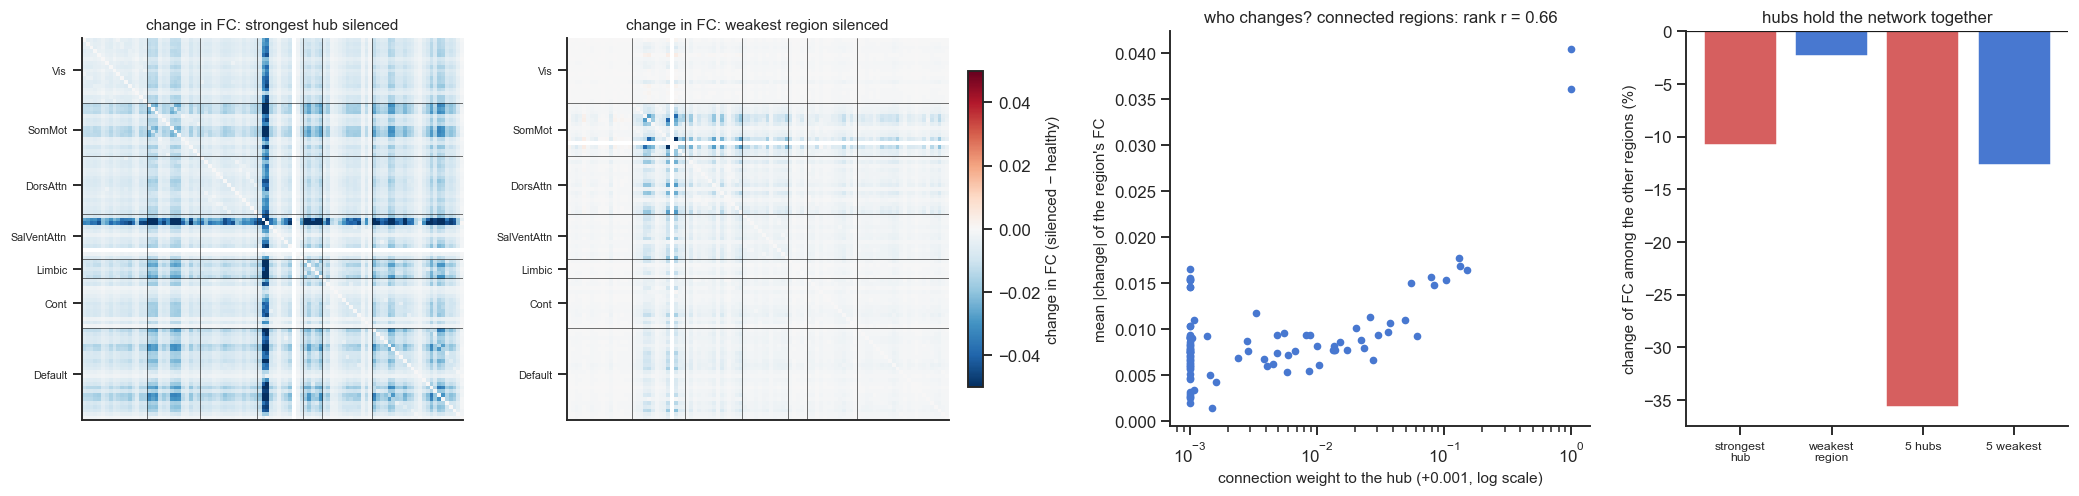

strongest hub  : -11 %
weakest region : -2 %
5 hubs         : -36 %
5 weakest      : -13 %


In [8]:
# @title Solution, steps 2-4: silencing
def silenced_fc(regions):
    a = np.full(100, A0); a[list(regions)] = -5.0
    return model_fc(a)

cases = {"strongest hub": rank[:1], "weakest region": rank[-1:], "5 hubs": rank[:5], "5 weakest": rank[-5:]}
results = {k: silenced_fc(v) for k, v in cases.items()}                 # about 30 s

fig, ax = plt.subplots(1, 4, figsize=(19, 4.4), gridspec_kw=dict(width_ratios=[1, 1, 1.1, 1]), layout="constrained")
fig.get_layout_engine().set(w_pad=0.15)
def without(M, regions):                                              # blank the silenced region's own row and column
    M = M.copy(); M[list(regions), :] = np.nan; M[:, list(regions)] = np.nan; return M
im = show_matrix(ax[0], without(results["strongest hub"] - base, cases["strongest hub"]), "change in FC: strongest hub silenced", vmax=0.05)
show_matrix(ax[1], without(results["weakest region"] - base, cases["weakest region"]), "change in FC: weakest region silenced", vmax=0.05)
plt.colorbar(im, ax=ax[1], shrink=0.8, label="change in FC (silenced − healthy)")
k = rank[0]; others = np.setdiff1d(np.arange(100), [k])
change = np.abs((results["strongest hub"] - base)[np.ix_(others, others)]).mean(1)
wk = (sc + sc.T)[k, others]
con = wk > 0                                                            # directly connected regions
rho = np.corrcoef(np.argsort(np.argsort(wk[con])), np.argsort(np.argsort(change[con])))[0, 1]   # rank (Spearman) correlation
ax[2].plot(wk + 1e-3, change, "o", ms=4); ax[2].set_xscale("log")
ax[2].set(xlabel="connection weight to the hub (+0.001, log scale)", ylabel="mean |change| of the region's FC",
          title=f"who changes? connected regions: rank r = {rho:.2f}")
drop = [100 * (fc_among_others(results[c], cases[c]) / fc_among_others(base, cases[c]) - 1) for c in cases]
ax[3].bar(["strongest\nhub", "weakest\nregion", "5 hubs", "5 weakest"], drop, color=["C3", "C0", "C3", "C0"]); ax[3].axhline(0, c="k", lw=0.8)
ax[3].set(ylabel="change of FC among the other regions (%)", title="hubs hold the network together"); ax[3].tick_params(axis="x", labelsize=8)
plt.show()
for c, d in zip(cases, drop): print(f"{c:15s}: {d:+.0f} %")

**Reading the solution.** Matrices (silenced region removed): silencing the strongest hub changes many connections
**between other regions**; the cross that remains is the hub's mirror region in the other hemisphere, its strongest
partner. Silencing the weakest region changes almost nothing. Third panel: among the regions wired to the hub, the
stronger the wire, the larger the change; the two points at weight ≈ 1 are mirror regions, and regions not wired to
the hub (left) change through indirect paths. Last panel: the FC among the remaining regions drops much more when hubs
are silenced (the five weakest regions together have about a third of the effect of the five hubs). **Hubs hold the
network together**: they relay the correlations between regions that are not directly wired.

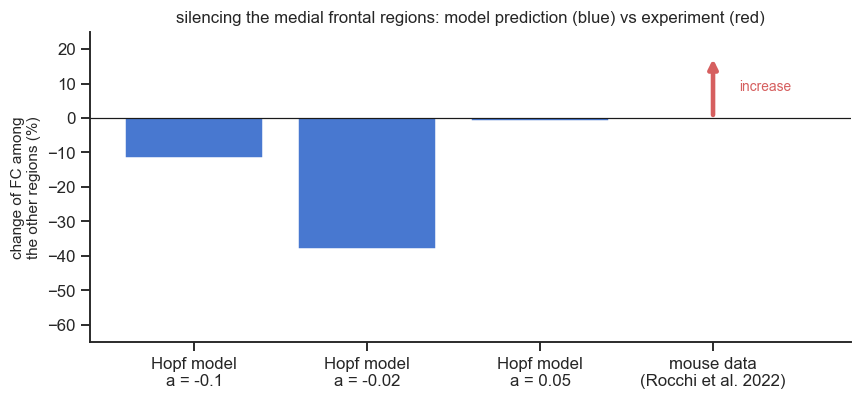

a = -0.10: FC among the other regions -12 %; pairs of regions whose FC increases: 0 %
a = -0.02: FC among the other regions -38 %; pairs of regions whose FC increases: 0 %
a = +0.05: FC among the other regions -1 %; pairs of regions whose FC increases: 0 %


In [9]:
# @title Solution, step 5: the mouse experiment in the Hopf model
mpfc = [i for i, l in enumerate(labels) if "SalVentAttn_Med" in l]
rows = []
for a0 in [A0, -0.02, 0.05]:
    healthy = base if a0 == A0 else model_fc(np.full(100, a0))
    a = np.full(100, a0); a[mpfc] = -5.0; sil = model_fc(a)
    keep = np.setdiff1d(np.arange(100), mpfc); d = (sil - healthy)[np.ix_(keep, keep)][np.triu_indices(len(keep), 1)]
    rows.append((a0, 100 * (fc_among_others(sil, mpfc) / fc_among_others(healthy, mpfc) - 1), 100 * (d > 0).mean()))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar([f"Hopf model\na = {r[0]:g}" for r in rows], [r[1] for r in rows], color="C0")
ax.annotate("", xy=(3, 18), xytext=(3, 0), arrowprops=dict(arrowstyle="-|>", color="C3", lw=3))
ax.set_xticks(range(4), [f"Hopf model\na = {r[0]:g}" for r in rows] + ["mouse data\n(Rocchi et al. 2022)"])
ax.text(3.15, 9, "increase", color="C3", fontsize=9, va="center")
ax.axhline(0, c="k", lw=0.8)
ax.set(ylabel="change of FC among\nthe other regions (%)", ylim=(-65, 25), xlim=(-0.6, 3.8),
       title="silencing the medial frontal regions: model prediction (blue) vs experiment (red)")
plt.tight_layout(); plt.show()
for a0, dch, up in rows: print(f"a = {a0:+.2f}: FC among the other regions {dch:+.0f} %; pairs of regions whose FC increases: {up:.0f} %")

## Hypothesis test: which model survives?

* **Prediction of the Hopf model:** silencing a frontal region **lowers** the FC among the other regions, at every
  working point, and not a single pair of regions increases its FC (Step 5).
* **Measurement** (slides; Rocchi et al. 2022): in mice, chemogenetic silencing of the prefrontal cortex **increases** FC.
* **Conclusion:** for this question the Hopf model is **rejected**. Near its working point it behaves almost like a
  linear relay: removing a relay can only remove correlations. A model has to be able to produce the opposite.
* **Revision:** a model with **bistable** regions (NB11), fitted to the mouse data before silencing, reproduces the
  increase (Rabuffo et al. 2025; slides). Its regions switch between down and up states, so a local change can
  reorganise the whole network instead of only removing a relay.

This is how a model is used as a laboratory: a prediction that can fail, a comparison with an experiment, and a revised
model when it does fail. In patients, damage to hubs does disrupt FC far beyond the lesion (Gratton et al. 2012; Aerts
et al. 2016), so the two kinds of result are not in conflict: which laboratory we choose decides which effects we can
see.

## Take-home

* One change, everything else identical (same brain, same noise): the model is a laboratory.
* Silencing a **hub** changes the FC of many other regions; silencing a peripheral region changes much less.
* A model can **fail** a test: the Hopf model predicts that silencing lowers FC, the mouse data show a rise, so a richer
  model (bistable regions) is needed for this question.
* **Next (NB14b):** instead of silencing a region, we **push** it and follow the push through the connectome.

### Homework
*To do at home, after the class.*
1. **The opposite.** Instead of silencing, push the hub **past** its bifurcation ($a=+0.3$). What happens to the FC
   among the other regions?
2. **Whole networks.** Set $a=-1$ in all regions of the default-mode network. Does the similarity to the measured FC go
   up or down? Compare with NB13b: which regions did myelin put far from the bifurcation?
3. **Random choice.** Silence five regions chosen at random, ten times. Where do the hubs fall in this distribution?

### References
* Deco G, Kringelbach ML, Jirsa VK, Ritter P (2017). The dynamics of resting fluctuations in the brain: metastability and
  its dynamical cortical core. *Sci Rep* 7:3095.
* Honey CJ, Sporns O (2008). Dynamical consequences of lesions in cortical networks. *Hum Brain Mapp* 29:802–809.
* Gratton C, Nomura EM, Pérez F, D'Esposito M (2012). Focal brain lesions to critical locations cause widespread
  disruption of the modular organization of the brain. *J Cogn Neurosci* 24:1275–1285.
* Rocchi F et al. (2022). Increased fMRI connectivity upon chemogenetic inhibition of the mouse prefrontal cortex.
  *Nat Commun* 13:1056.
* Rabuffo G et al. (2025). Mapping global brain reconfigurations following local targeted manipulations. *PNAS*
  122:e2405706122.
* Aerts H, Fias W, Caeyenberghs K, Marinazzo D (2016). Brain networks under attack: robustness properties and the
  impact of lesions. *Brain* 139:3063–3083.